In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


Sample Loan Dataset
   Income     Education     Employment  LoanAmount  CreditHistory  \
0  136958  Not Graduate  Self-employed      441947              0   
1  146932  Not Graduate  Self-employed      391602              1   
2  118694      Graduate  Self-employed      392528              1   
3  134879  Not Graduate  Self-employed       88926              0   
4  125268  Not Graduate       Salaried      157069              1   

  MaritalStatus LoanStatus  
0        Single   Rejected  
1        Single   Rejected  
2       Married   Rejected  
3       Married   Rejected  
4        Single   Approved  

Model Evaluation
Model Accuracy: 87.00%

Classification Report:
              precision    recall  f1-score   support

    Approved       0.89      0.89      0.89       118
    Rejected       0.84      0.84      0.84        82

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200


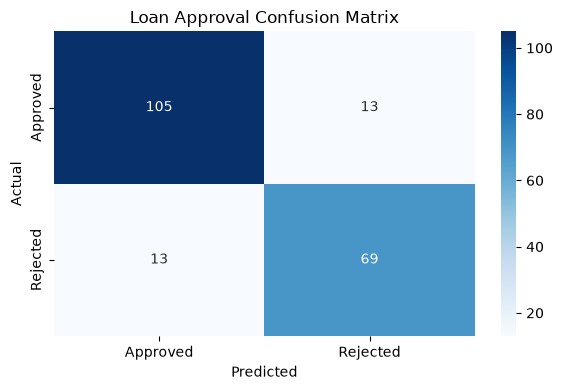

Model saved as loan_approval_model.pkl

Enter Applicant Details


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Generate sample loan dataset
np.random.seed(42)
n = 1000

df = pd.DataFrame({
    "Income": np.random.randint(15000, 150000, n),
    "Education": np.random.choice(["Graduate", "Not Graduate"], n),
    "Employment": np.random.choice(["Salaried", "Self-employed"], n),
    "LoanAmount": np.random.randint(20000, 500000, n),
    "CreditHistory": np.random.choice([0, 1], n, p=[0.25, 0.75]),
    "MaritalStatus": np.random.choice(["Married", "Single"], n)
})

# Generate sample target labels
score = (
    (df["Income"] >= 40000).astype(int)
    + (df["CreditHistory"] == 1).astype(int) * 3
    + (df["Education"] == "Graduate").astype(int)
    + (df["Employment"] == "Salaried").astype(int)
    - (df["LoanAmount"] > 300000).astype(int) * 2
    + np.random.normal(0, 0.8, n)
)

df["LoanStatus"] = np.where(score >= 3, "Approved", "Rejected")

print("Sample Loan Dataset")
print(df.head())

# Separate features and target
X = df.drop("LoanStatus", axis=1)
y = df["LoanStatus"]

categorical_features = [
    "Education", "Employment", "MaritalStatus"
]
numerical_features = [
    "Income", "LoanAmount", "CreditHistory"
]

# Preprocessing
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("numerical", StandardScaler(), numerical_features)
])

# Create machine learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100, random_state=42
    ))
])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train model
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Evaluation")
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot confusion matrix
cm = confusion_matrix(
    y_test, y_pred, labels=["Approved", "Rejected"]
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Approved", "Rejected"],
    yticklabels=["Approved", "Rejected"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Loan Approval Confusion Matrix")
plt.tight_layout()
plt.show()

# Save trained model
joblib.dump(model, "loan_approval_model.pkl")
print("Model saved as loan_approval_model.pkl")

# Take applicant details from user
print("\nEnter Applicant Details")

income = float(input("Monthly Income (Rs): "))
education = input("Education (Graduate/Not Graduate): ").strip().title()
employment = input("Employment (Salaried/Self-employed): ").strip().title()
loan_amount = float(input("Loan Amount (Rs): "))
credit_history = int(input("Credit History (1=Good, 0=Poor): "))
marital_status = input("Marital Status (Married/Single): ").strip().title()

if (
    income <= 0 or loan_amount <= 0
    or education not in ["Graduate", "Not Graduate"]
    or employment not in ["Salaried", "Self-employed"]
    or credit_history not in [0, 1]
    or marital_status not in ["Married", "Single"]
):
    print("Invalid input. Please check the entered details.")

else:
    applicant = pd.DataFrame([{
        "Income": income,
        "Education": education,
        "Employment": employment,
        "LoanAmount": loan_amount,
        "CreditHistory": credit_history,
        "MaritalStatus": marital_status
    }])

    prediction = model.predict(applicant)[0]
    probabilities = model.predict_proba(applicant)[0]
    confidence = np.max(probabilities) * 100

    print("\nLoan Prediction Result")
    print("Predicted Status:", prediction)
    print(f"Model Confidence: {confidence:.2f}%")
    print("Note: This is an educational prediction, not a real loan decision.")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Generate a sample disease dataset
np.random.seed(42)

symptoms = [
    "Fever", "Cough", "Headache", "Fatigue",
    "Sore_Throat", "Body_Pain", "Sneezing", "Nausea"
]

diseases = [
    "Flu", "Common_Cold", "Migraine",
    "Allergy", "Stomach_Infection"
]

# Symptom probabilities for each sample disease category
probabilities = np.array([
    [0.85, 0.80, 0.65, 0.85, 0.70, 0.80, 0.20, 0.35],
    [0.25, 0.75, 0.30, 0.45, 0.80, 0.25, 0.85, 0.10],
    [0.15, 0.10, 0.95, 0.65, 0.10, 0.25, 0.10, 0.35],
    [0.10, 0.25, 0.15, 0.25, 0.20, 0.10, 0.90, 0.05],
    [0.55, 0.10, 0.25, 0.60, 0.10, 0.40, 0.10, 0.90]
])

# Create synthetic patient records
n = 1500
labels = np.random.choice(len(diseases), size=n)
X = np.zeros((n, len(symptoms)), dtype=int)

for i in range(n):
    X[i] = np.random.binomial(1, probabilities[labels[i]])

df = pd.DataFrame(X, columns=symptoms)
df["Disease"] = [diseases[i] for i in labels]

print("Sample Disease Dataset")
print(df.head())

# Split features and target
X = df[symptoms]
y = df["Disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create classification models
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

# Train and evaluate models
results = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    results[name] = accuracy * 100
    trained_models[name] = model

    print(f"\n{name} Accuracy: {accuracy * 100:.2f}%")

# Compare model accuracy
print("\nClassification Model Comparison")
for name, accuracy in results.items():
    print(f"{name}: {accuracy:.2f}%")

plt.figure(figsize=(8, 5))
sns.barplot(x=list(results.keys()), y=list(results.values()))
plt.title("Disease Prediction Model Accuracy")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Evaluate the best model
best_name = max(results, key=results.get)
best_model = trained_models[best_name]

print("\nBest Model:", best_name)

test_predictions = best_model.predict(X_test)

print("\nClassification Report")
print(classification_report(
    y_test, test_predictions, zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test, test_predictions, labels=diseases
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=diseases, yticklabels=diseases
)
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.title("Disease Prediction Confusion Matrix")
plt.tight_layout()
plt.show()

# Save the best model
joblib.dump(
    {"model": best_model, "symptoms": symptoms},
    "disease_prediction_model.pkl"
)
print("Model saved successfully!")

# Take symptoms from the user
print("\nEnter Patient Symptoms")
print("Enter 1 for Yes and 0 for No.")

patient_data = []

for symptom in symptoms:
    while True:
        try:
            value = int(input(f"{symptom.replace('_', ' ')} (0/1): "))
            if value in [0, 1]:
                patient_data.append(value)
                break
            print("Please enter only 0 or 1.")
        except ValueError:
            print("Invalid input. Please enter 0 or 1.")

patient = pd.DataFrame([patient_data], columns=symptoms)

prediction = best_model.predict(patient)[0]

print("\nDisease Prediction Result")
print("Possible category:", prediction)
print("This is an educational prediction, not a medical diagnosis.")